# PCW Lesson 11: Data Ethics

**Student**: Katia Gwaneza Nkurunziza
**Date**: Session 11, Fall 2026
**Covers**: Questions 3-5 of 6 (the coding/modeling portion). Questions 1-2 are conceptual (no code) and are answered in markdown below. The ethics discussion for Question 3 lives in this session's `README.md`, it is not duplicated here.

## Important: Substitute Datasets

The original assignment links to "this homicide data" and "this data about house prices" through hyperlinks on a web page. Those hyperlinks were not captured as URLs in the PDF export of the assignment available here, so the exact intended datasets are unrecoverable.

**What's used instead**, chosen to match the same exercise shape (a city crime dataset with location, a housing dataset with location):

1. **Chicago homicide data (2021-2025)**: City of Chicago Data Portal, "Crimes - 2001 to Present" dataset (id `ijzp-q8t2`), filtered to `primary_type = 'HOMICIDE'`, aggregated by community area. Pulled live via the Socrata API, `https://data.cityofchicago.org/resource/ijzp-q8t2.csv`.
2. **Ames, Iowa housing data**: the De Cock (2011) Ames Housing dataset, the same data underlying the well-known Kaggle "House Prices: Advanced Regression Techniques" competition. Pulled directly from its original academic host, `https://jse.amstat.org/v19n3/decock/AmesHousing.txt`.

Both are real, public, and fetchable directly over HTTP with no API key. If the original linked datasets turn up later, swap the loading cell below, the rest of the analysis pattern (train/test split, regression, neighborhood visualization) carries over unchanged.

## Assignment Scenario (verbatim)

"Imagine you're a data scientist living in a major city. You have two major clients: the city police department, and a bank. The police department has provided you with this homicide data for the city. The bank has provided you with this data about house prices."

- **Q1**: What kind of models might be useful to the police department? Describe how you could combine the two data sets to improve your predictions.
- **Q2**: What kind of models might be of use to the bank? Describe how you could combine the two data sets to improve your predictions.
- **Q3**: What are some of the ethical considerations in using these data sets? *(Covered in the README's ethics discussion, not repeated here.)*
- **Q4**: Using code, create a prediction using one of the data sets above and describe how this might be useful to your client.
- **Q5**: Be ready to present your model in class.
- **Extension**: The datasets above include an important variable: location. Using code, pick one city and visualize the data (homicides or house prices), by neighborhood. What patterns do you notice?

## Q1: Models for the Police Department

**What kind of models might be useful?**

- **Spatial hotspot models** (kernel density estimation, or clustering like DBSCAN on lat/long) to find where homicides concentrate, for patrol allocation.
- **Time-series forecasting** (ARIMA, or just a rolling average by week/month) of incident counts per community area, to anticipate seasonal or trend shifts rather than just reacting after the fact.
- **Classification models** predicting whether a given area is high-risk in a given month, if enough historical features are available (prior incident density, time of year, day of week).

**Combining with the housing data**: housing data carries vacancy status, sale frequency, and price-trend by neighborhood. A neighborhood with a spike in vacant/abandoned properties or a collapsing sale-price trend is a documented correlate of rising violent crime (disinvestment leading to reduced informal social control). Feeding **housing vacancy rate and price-change-over-time, by neighborhood,** into the hotspot/forecasting model as an extra feature could sharpen *where* resources are predicted to be needed, sometimes before the crime data alone shows it.

**This is also exactly where it gets risky,** see the flag at the end of Q2.

## Q2: Models for the Bank

**What kind of models might be useful?**

- **Regression models** (linear regression, random forest regression) predicting house sale price from structural features (square footage, quality, age, etc.), the bread-and-butter valuation/appraisal model.
- **Risk/default models**: predicting loan default risk for mortgage underwriting, typically logistic regression or gradient boosting on borrower and property features.

**Combining with the homicide data**: a bank could add **neighborhood-level homicide counts or trend** as a feature in either the valuation model (crime correlates with price) or the risk model (crime correlates with foreclosure/default risk in some underwriting research).

### Ethical flag (ties to Q3)

This is precisely where combining the two datasets stops being a neutral modeling choice. Feeding crime data, which is itself a record of *policing* as much as of crime, into a valuation or lending model risks reconstructing **redlining**: a model that scores a neighborhood down for its historical crime rate denies credit or inflates risk for residents of that neighborhood regardless of their individual creditworthiness, and because historical over-policing in Black and Latino neighborhoods inflates recorded crime independent of actual crime rates, the model launders a proxy for race through a seemingly neutral "crime" feature. Symmetrically, feeding housing-price *decline* into a predictive-policing resource-allocation model creates a **feedback loop**: more patrols get sent to already-under-invested, lower-price neighborhoods, generating more recorded incidents there simply because more officers are looking, which then justifies sending even more patrols next cycle, regardless of where crime is actually occurring. Neither direction of combining these datasets is ethically free. Both are discussed further in the README.

## Q3: Ethical Considerations

Not answered here. Full discussion (bias in homicide/arrest data as a record of policing rather than crime, redlining-style proxy discrimination, feedback loops, aggregation bias from using substitute data instead of the original intended dataset) is in this session's `README.md` under "Ethical Considerations."

## Code Cell 1 of 3: Load the Substitute Datasets

Loads the cached CSVs in `data/` (re-downloaded from the live sources above if the cache is missing). Chicago homicide counts are aggregated server-side by `community_area`, Chicago's official neighborhood numbering (1-77); names are attached from the fixed, publicly documented City of Chicago community area list.

In [1]:
import os
import pandas as pd
import requests

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)  # local cache so this notebook can run offline after the first pull

# --- Chicago homicide counts by community area (2021-2025) ---
homicide_path = os.path.join(DATA_DIR, "chicago_homicide_by_community_area_2021_2025.csv")
if not os.path.exists(homicide_path):
    # Socrata's SoQL query API: filter to HOMICIDE rows in 2021-2025, then group-and-count
    # server-side so we only download the small aggregated result, not every raw crime record.
    url = (
        "https://data.cityofchicago.org/resource/ijzp-q8t2.csv"
        "?$select=community_area,count(*) as cnt"
        "&$where=primary_type='HOMICIDE' AND year >= 2021 AND year <= 2025"
        "&$group=community_area&$order=cnt desc&$limit=100"
    )
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()  # fail loudly if the API is down, instead of silently caching an error page
    with open(homicide_path, "wb") as f:
        f.write(resp.content)

homicide = pd.read_csv(homicide_path)
homicide["community_area"] = homicide["community_area"].astype(int)  # comes back as float/str from the API

# Fixed, official City of Chicago community area numbering (1-77), unchanged since the 1930s.
# The API only returns numeric IDs, so this lookup table is what turns "25" into "Austin" for display.
COMMUNITY_AREA_NAMES = {
    1: "Rogers Park", 2: "West Ridge", 3: "Uptown", 4: "Lincoln Square", 5: "North Center",
    6: "Lake View", 7: "Lincoln Park", 8: "Near North Side", 9: "Edison Park", 10: "Norwood Park",
    11: "Jefferson Park", 12: "Forest Glen", 13: "North Park", 14: "Albany Park", 15: "Portage Park",
    16: "Irving Park", 17: "Dunning", 18: "Montclare", 19: "Belmont Cragin", 20: "Hermosa",
    21: "Avondale", 22: "Logan Square", 23: "Humboldt Park", 24: "West Town", 25: "Austin",
    26: "West Garfield Park", 27: "East Garfield Park", 28: "Near West Side", 29: "North Lawndale",
    30: "South Lawndale", 31: "Lower West Side", 32: "Loop", 33: "Near South Side", 34: "Armour Square",
    35: "Douglas", 36: "Oakland", 37: "Fuller Park", 38: "Grand Boulevard", 39: "Kenwood",
    40: "Washington Park", 41: "Hyde Park", 42: "Woodlawn", 43: "South Shore", 44: "Chatham",
    45: "Avalon Park", 46: "South Chicago", 47: "Burnside", 48: "Calumet Heights", 49: "Roseland",
    50: "Pullman", 51: "South Deering", 52: "East Side", 53: "West Pullman", 54: "Riverdale",
    55: "Hegewisch", 56: "Garfield Ridge", 57: "Archer Heights", 58: "Brighton Park", 59: "McKinley Park",
    60: "Bridgeport", 61: "New City", 62: "West Elsdon", 63: "Gage Park", 64: "Clearing",
    65: "West Lawn", 66: "Chicago Lawn", 67: "West Englewood", 68: "Englewood",
    69: "Greater Grand Crossing", 70: "Ashburn", 71: "Auburn Gresham", 72: "Beverly",
    73: "Washington Heights", 74: "Mount Greenwood", 75: "Morgan Park", 76: "O'Hare", 77: "Edgewater",
}
homicide["neighborhood"] = homicide["community_area"].map(COMMUNITY_AREA_NAMES)

# --- Ames, Iowa housing data ---
housing_path = os.path.join(DATA_DIR, "AmesHousing.txt")
if not os.path.exists(housing_path):
    # De Cock (2011)'s original tab-separated release, hosted by the Journal of Statistics Education.
    # This is the same data behind Kaggle's "House Prices" competition, pulled from the primary source.
    url = "https://jse.amstat.org/v19n3/decock/AmesHousing.txt"
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    with open(housing_path, "wb") as f:
        f.write(resp.content)

housing = pd.read_csv(housing_path, sep="\t")  # tab-separated, not comma, this file uses \t

# Quick sanity check: print a few rows from each dataset so we can visually confirm
# the loads worked and the columns look like what we expect before modeling on them.
print(f"Homicide data: {len(homicide)} community areas, {homicide['cnt'].sum()} total homicides, 2021-2025")
print(homicide[["neighborhood", "cnt"]].sort_values("cnt", ascending=False).head(5).to_string(index=False))
print()
print(f"Housing data: {housing.shape[0]} sales, {housing.shape[1]} columns")
print(housing[["Neighborhood", "SalePrice", "Gr Liv Area", "Overall Qual"]].head(3).to_string(index=False))

Homicide data: 76 community areas, 3227 total homicides, 2021-2025
          neighborhood  cnt
                Austin  264
           South Shore  167
Greater Grand Crossing  152
        North Lawndale  148
        Auburn Gresham  146

Housing data: 2930 sales, 82 columns
Neighborhood  SalePrice  Gr Liv Area  Overall Qual
       NAmes     215000         1656             6
       NAmes     105000          896             5
       NAmes     172000         1329             6


## Q4: A Real Prediction (Bank Use Case)

Using the Ames housing data to predict `SalePrice` from a handful of structural features, the bread-and-butter valuation model a bank's appraisal or underwriting team would use. `Neighborhood` is deliberately excluded from the feature list, see the interpretation below for why.

In [2]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Only structural/physical features of the house, no location data at all.
# Neighborhood is left out on purpose: it's the feature most likely to act as a
# proxy for historically protected characteristics (see the ethics discussion in
# the README), so a valuation model aimed at fairness shouldn't lean on it.
features = ["Overall Qual", "Gr Liv Area", "Year Built", "Total Bsmt SF", "Garage Cars", "Full Bath", "Lot Area"]

# A handful of rows have missing values in these columns (e.g. no garage -> NaN garage count).
# Dropping them is simplest and, since it's only 2 of 2930 rows here, doesn't meaningfully bias the fit.
model_df = housing[features + ["SalePrice"]].dropna()
print(f"Rows used after dropping missing values: {len(model_df)} / {len(housing)}")

X = model_df[features]
y = model_df["SalePrice"]
# Fixed random_state so this split, and therefore every metric below, is reproducible on rerun.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

reg = LinearRegression()
reg.fit(X_train, y_train)          # learn coefficients from the training 80% only
preds = reg.predict(X_test)        # evaluate on the held-out 20% the model never saw

# Three different views of the same error: R^2 (variance explained, scale-free),
# RMSE (typical error in dollars, penalizes big misses more), MAE (typical error
# in dollars, treats all misses equally). Reporting more than one avoids the trap
# of a single metric hiding how the model actually fails.
r2 = r2_score(y_test, preds)
rmse = np.sqrt(mean_squared_error(y_test, preds))  # mean_squared_error + manual sqrt for compatibility
mae = mean_absolute_error(y_test, preds)

print(f"\nTest R^2: {r2:.3f}")
print(f"Test RMSE: ${rmse:,.0f}")
print(f"Test MAE: ${mae:,.0f}")
print(f"Mean sale price in test set: ${y_test.mean():,.0f}")

# Coefficients show which features move the price prediction most, and in which
# direction, useful for explaining the model in plain terms, not just its score.
print("\nCoefficients:")
for feat, coef in zip(features, reg.coef_):
    print(f"  {feat}: {coef:,.2f}")

Rows used after dropping missing values: 2928 / 2930

Test R^2: 0.786
Test RMSE: $41,984
Test MAE: $24,741
Mean sale price in test set: $183,635

Coefficients:
  Overall Qual: 21,423.23
  Gr Liv Area: 51.91
  Year Built: 390.65
  Total Bsmt SF: 28.31
  Garage Cars: 11,806.31
  Full Bath: -8,162.06
  Lot Area: 0.78


**Result**: R^2 = 0.786 on held-out test data, meaning these 7 features explain about 79% of the variance in sale price. RMSE is $41,984 on a test-set mean sale price of $183,635, so typical prediction error is roughly 23% of an average home's value.

**Usefulness to the bank**: this is a starting-point automated valuation model (AVM). A bank could use it to flag appraisals that fall far outside the model's predicted range for manual review, catching both overvaluation (a lending risk) and undervaluation (a missed-opportunity or discrimination risk), or to triage which properties need a full in-person appraisal versus a faster desktop review. $42K of typical error is too large to replace a human appraiser outright, this is a screening tool, not a final valuation. The model is also restricted to physical features of the home only, it never touches `Neighborhood`, deliberately, to sidestep the location-based proxy-discrimination risk raised in Q2's ethical flag.

## Q5: Presenting the Model

Be ready to explain in class: what features the model uses, what R^2 and RMSE mean in plain terms, why `Neighborhood` was deliberately left out of the feature list (ties back to the Q2 ethical flag on location-based proxy discrimination), and the model's practical use (triage tool, not a replacement for a human appraiser) and its limits ($42K typical error).

## Extension: Visualizing by Neighborhood

Picking Chicago, visualizing homicide counts (2021-2025) by community area, Chicago's official neighborhood unit.

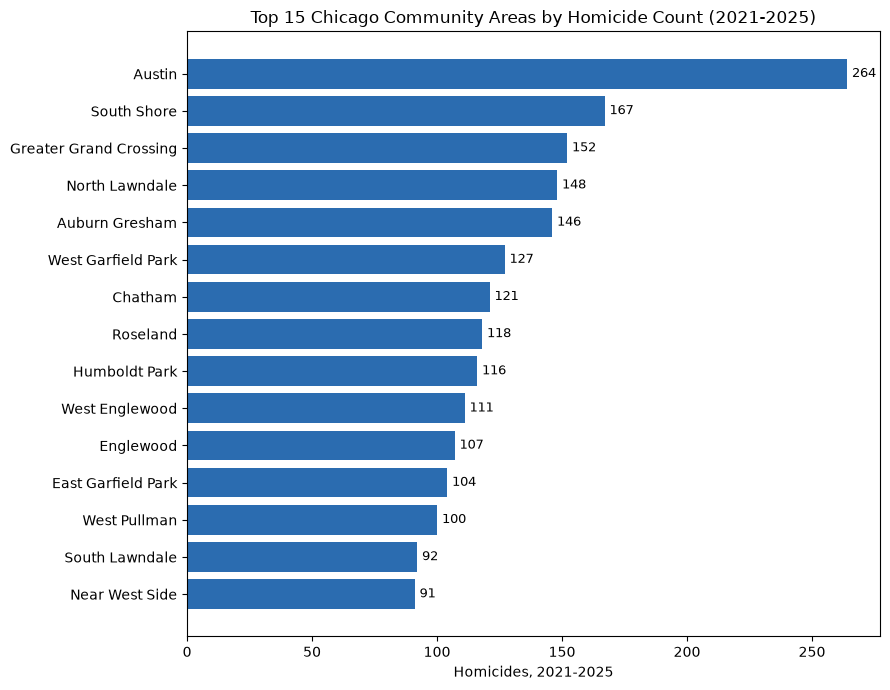

Top area: Austin with 264 homicides
Total homicides across all 76 community areas: 3227
Share of citywide total in top 15 areas: 60.9%


In [3]:
import matplotlib.pyplot as plt

top_n = 15
# Sort descending to find the top 15, then re-sort ascending so barh() draws
# the largest bar at the top of the chart (barh plots bottom-to-top by default).
top_areas = homicide.sort_values("cnt", ascending=False).head(top_n).sort_values("cnt")

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_areas["neighborhood"], top_areas["cnt"], color="#2b6cb0")
ax.set_xlabel("Homicides, 2021-2025")
ax.set_title(f"Top {top_n} Chicago Community Areas by Homicide Count (2021-2025)")
# Label each bar with its exact count, easier to read precisely than estimating from bar length alone.
for y, count in enumerate(top_areas["cnt"]):
    ax.text(count + 2, y, str(count), va="center", fontsize=9)
plt.tight_layout()
plt.show()

# Numbers to back up the pattern description below, not just the visual impression.
print(f"Top area: {top_areas.iloc[-1]['neighborhood']} with {top_areas.iloc[-1]['cnt']} homicides")
print(f"Total homicides across all {len(homicide)} community areas: {homicide['cnt'].sum()}")
print(f"Share of citywide total in top {top_n} areas: {top_areas['cnt'].sum() / homicide['cnt'].sum():.1%}")

**Pattern observed**: homicides over 2021-2025 are heavily concentrated in a specific geographic band. Every one of the top 15 community areas is on the city's West Side (Austin, North Lawndale, West Garfield Park, East Garfield Park, Humboldt Park, South Lawndale, Near West Side) or South Side (South Shore, Greater Grand Crossing, Auburn Gresham, Chatham, Roseland, West Englewood, Englewood, West Pullman). None of the North Side community areas (Lincoln Park, Lake View, Uptown, and so on) appear in the top 15 at all. The single highest area, Austin, recorded 264 homicides, about 1.6x the next-highest, South Shore (167). The top 15 areas alone account for roughly 61% of all homicides citywide over the period, despite being only 15 of the city's 77 community areas. This is the exact geography that would feed into a predictive-policing resource-allocation model, and it overlaps heavily with historically disinvested, majority-Black neighborhoods, which is precisely the aggregation that risks the feedback loop flagged in Q2: concentrating patrols here generates more recorded incidents here, reinforcing the same pattern in next year's data regardless of where crime is actually shifting.

## Summary

- **Q1/Q2**: police benefit from spatial hotspot and time-series models; banks benefit from valuation and risk-scoring regressions. Combining the two datasets is technically easy (join by neighborhood) and ethically loaded in both directions, see the redlining and feedback-loop flags above and the full discussion in `README.md`.
- **Q3**: covered in `README.md`.
- **Q4**: a 7-feature linear regression on the Ames housing data explains about 79% of sale-price variance (R^2 = 0.786) with roughly $42K typical error, useful to a bank as an appraisal-triage screen, not a final valuation, and it deliberately excludes neighborhood/location features.
- **Extension**: Chicago's 2021-2025 homicide data is sharply concentrated on the West and South Sides, with Austin alone recording 264 of the city's homicides over the period.